# Propagation onto tilted planes

Detectors, mirrors, wafers and fibre facets are often not perpendicular to
the beam. The usual propagators connect *parallel* planes; `pyoptics.tilted`
connects the plane $z = 0$ with a plane through $\mathbf r_0 = (0, 0, z_0)$
whose axes are the columns of a rotation matrix $R$:

$$ \hat{\mathbf x} = R\,\mathbf e_x, \qquad \hat{\mathbf y} = R\,\mathbf e_y, \qquad
   \hat{\mathbf n} = R\,\mathbf e_z, \qquad
   \mathbf r(\hat x, \hat y) = \mathbf r_0 + \hat x\,\hat{\mathbf x} + \hat y\,\hat{\mathbf y}. $$

A plane wave $e^{i\mathbf k\cdot\mathbf r}$ of the source spectrum arrives as
$e^{i\mathbf k\cdot\mathbf r_0}\,e^{i(\hat k_x \hat x + \hat k_y \hat y)}$ with the rotated
wave vector $\hat{\mathbf k} = R^T \mathbf k$. The field on the tilted plane is again a plane
wave sum in the plane's own coordinates, but over a *non-uniform* set of
frequencies $\hat k_x, \hat k_y$. Two methods evaluate it:

| `method` | How | Cost |
|---|---|---|
| `"exact"` | the non-uniform sum itself; separable (one matrix product per spectrum row) for rotations about $x$ or $y$, finufft type 3 or a direct sum otherwise | $O(N^3)$ |
| `"rotation"` | Matsushima (2003): uniform $\hat k$ grid, map back with $\mathbf k = R\hat{\mathbf k}$, interpolate the source spectrum, multiply by the Jacobian $k_z/\hat k_z$, one inverse FFT | $O(N^2\log N)$ |

| Function | What it does |
|---|---|
| `tilted_plane()` | scalar field on a tilted plane (or, with `reverse=True`, from a tilted plane to a parallel one) |
| `vectorial_tilted_plane()` | the same for $[E_x, E_y]$, components in the plane's axes $\hat E = R^T E$ |
| `rotate_angular_spectrum()` | the building block of `"rotation"` |
| `tilted_beam_widths()` | ISO 11146 widths on an inclined plane |
| `power_flux()` | power through a plane from the angular spectrum |

Conventions as everywhere in pyoptics: fields vary as $\exp(i(\mathbf k\cdot\mathbf r-\omega t))$,
grids are centered ($x = 0$ at index $N/2$), lengths are in units of the wavelength.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.tilted import (tilted_plane, vectorial_tilted_plane, rotate_angular_spectrum,
                             tilted_beam_widths, power_flux, rotation_from_angles)
from pyoptics.geometry import R_y
from pyoptics.propagators import rayleigh_sommerfeld_I_TF, propagate_padded
from pyoptics.abcd import gaussian_field
from pyoptics.utils import grid1d, frequencies
from pyoptics.fft import FT, inv_FT

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})
WL = 1.0
K = 2*np.pi/WL

def gaussian(x, y, w0, x0=0.0):
    return gaussian_field(x, y, 1j*np.pi*w0**2/WL, WL, x0=x0)

def gaussian_3d(P, w0):
    # paraxial Gaussian beam with its waist at z = 0 (with Gouy phase) at the points P
    z_R = np.pi*w0**2/WL
    return (gaussian_field(P[0], P[1], P[2] + 1j*z_R, WL)*np.exp(1j*K*P[2])
            *np.exp(-1j*np.arctan(P[2]/z_R)))

def plane_points(r0, R, x_t, y_t):
    X, Y = np.meshgrid(x_t, y_t)
    return np.asarray(r0, float)[:, None, None] + R[:, 0, None, None]*X + R[:, 1, None, None]*Y

## 1. Geometry: a Gaussian beam cut by inclined planes

A Gaussian beam ($w_0 = 6\lambda$, waist at $z = 0$) and three planes through
$z_0 = 80\lambda$, tilted about the $y$ axis by $\theta = 0°, 30°, 60°$. Left: the
side view $|u(x, 0, z)|^2$ from parallel angular spectrum propagation, with the
planes. Right: $|u|^2$ along the $\hat x$ axis of each plane. The footprint stretches by
$1/\cos\theta$, and a tilted plane spans $z_0 \mp \hat x\sin\theta$: its two halves see the beam
at different distances, so the cut is slightly asymmetric.

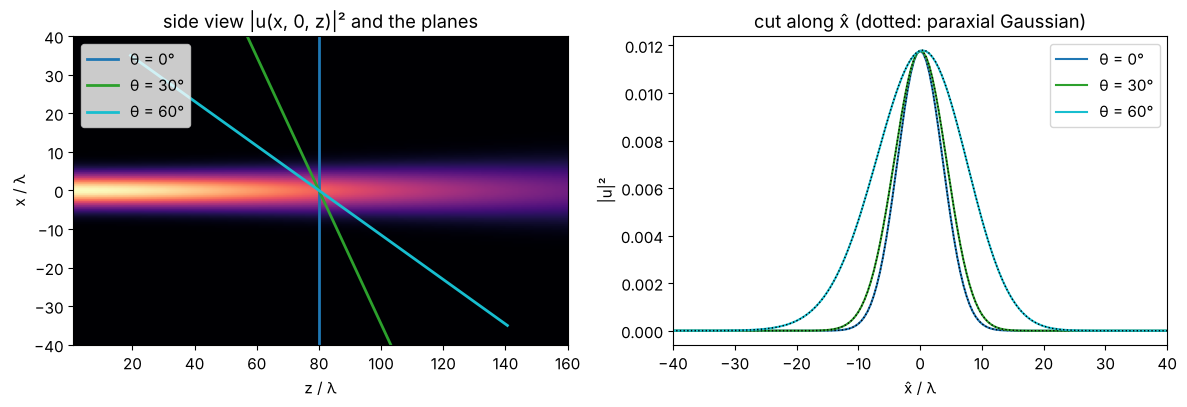

In [2]:
N, L, w0, z0 = 256, 128.0, 6.0, 80.0
x = grid1d(-L/2, L/2, N); y = x.copy()
u0 = gaussian(x, y, w0)

z_side = np.linspace(1, 160, 160)
side = np.array([np.abs(propagate_padded(rayleigh_sommerfeld_I_TF, u0, x, y, z, WL)[0][N//2])**2
                 for z in z_side])

x_out = grid1d(-80, 80, 320)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.imshow(side.T, extent=[z_side[0], z_side[-1], x[0], x[-1]], aspect="auto", cmap="magma")
for th, col in zip((0, 30, 60), ("C0", "C2", "C9")):
    R = R_y(np.radians(th))
    s = np.linspace(-70, 70, 2)
    ax1.plot(z0 + R[2, 0]*s, R[0, 0]*s, col, lw=2, label="θ = {}°".format(th))
    u_t, x_t, y_t, c = tilted_plane(u0, x, y, z0, WL, R=R, x_out=x_out, y_out=np.array([0.0]),
                                    method="exact")
    ax2.plot(x_t, np.abs(u_t[0])**2, col, label="θ = {}°".format(th))
    ax2.plot(x_t, np.abs(gaussian_3d(plane_points([0, 0, z0], R, x_t, [0.0]), w0)[0])**2,
             "k:", lw=1)
ax1.set(xlabel="z / λ", ylabel="x / λ", ylim=(-40, 40), title="side view |u(x, 0, z)|² and the planes")
ax1.legend(loc="upper left")
ax2.set(xlabel="x̂ / λ", ylabel="|u|²", xlim=(-40, 40), title="cut along x̂ (dotted: paraxial Gaussian)")
ax2.legend()
plt.tight_layout()

## 2. A beam on an inclined detector: intensity, phase and carrier

On a tilted plane the on-axis beam has the transverse wavenumber
$\hat k_x = -k\sin\theta$: the phase advances by $2\pi$ every $\lambda/\sin\theta$ along $\hat x$, a
fringe pattern that would need $\Delta \hat x < \lambda/(2\sin\theta)$ to be sampled. With
`remove_carrier=True` (default) this mean tilt is taken out and returned as
`k_carrier`; the remaining phase is the curvature of the beam. The plots show
$|u_t|^2$ and the phase without and with the carrier, for $\theta = 60°$ on a
$\lambda/4$ grid (where the carrier phase is still resolved).

carrier k_x^ = -5.4376, -k sin(theta) = -5.4414


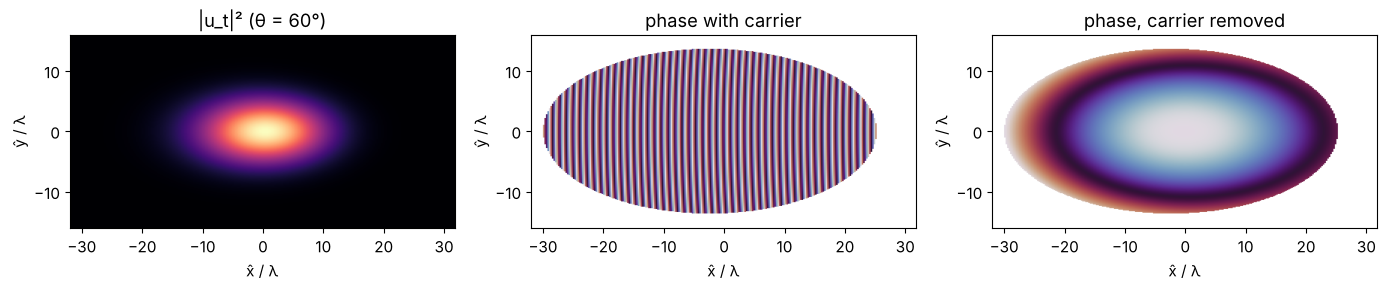

In [3]:
R = R_y(np.radians(60))
xo = grid1d(-32, 32, 256)
u_c, x_t, y_t, _ = tilted_plane(u0, x, y, z0, WL, R=R, x_out=xo, y_out=xo/2, remove_carrier=False)
u_t, x_t, y_t, c = tilted_plane(u0, x, y, z0, WL, R=R, x_out=xo, y_out=xo/2)
print("carrier k_x^ = {:.4f}, -k sin(theta) = {:.4f}".format(c[0], -K*np.sin(np.radians(60))))

ext = [x_t[0], x_t[-1], y_t[0], y_t[-1]]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
axs[0].imshow(np.abs(u_t)**2, extent=ext, cmap="magma"); axs[0].set_title("|u_t|² (θ = 60°)")
mask = np.abs(u_t)**2 > 1E-3*np.max(np.abs(u_t)**2)
axs[1].imshow(np.where(mask, np.angle(u_c), np.nan), extent=ext, cmap="twilight")
axs[1].set_title("phase with carrier")
axs[2].imshow(np.where(mask, np.angle(u_t), np.nan), extent=ext, cmap="twilight")
axs[2].set_title("phase, carrier removed")
for ax in axs:
    ax.set(xlabel="x̂ / λ", ylabel="ŷ / λ")
plt.tight_layout()

### Beam widths on inclined planes

`tilted_beam_widths()` measures the ISO 11146 second moment widths of $|u_t|^2$ in
the plane's coordinates. For a nearly collimated beam the width along $\hat x$
grows as $d/\cos\theta$ while $d_{\hat y}$ stays: a tilted camera reports an elliptical
beam. Dividing by $1/\cos\theta$ recovers the true width (here $w_0 = 8\lambda$ at
$z_0 = 200\lambda$, $d = 2w(z_0)$).

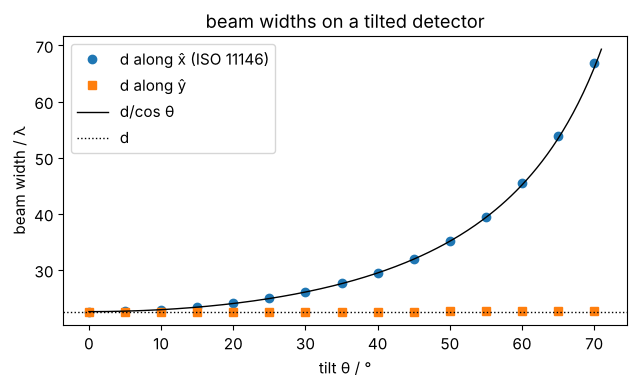

In [4]:
w0b, z0b = 8.0, 200.0
ub = gaussian(x, y, w0b)
d_true = 2*w0b*np.sqrt(1 + (z0b/(np.pi*w0b**2))**2)
thetas = np.arange(0, 71, 5)
dx, dy = [], []
for th in thetas:
    widths, *_ = tilted_beam_widths(ub, x, y, z0b, WL, R=R_y(np.radians(th)),
                                    x_out=grid1d(-180, 180, 512), y_out=grid1d(-50, 50, 128))
    phi = widths.phi % np.pi
    along_x = abs(np.cos(phi)) > abs(np.sin(phi))
    dx.append(widths.d_x if along_x else widths.d_y)
    dy.append(widths.d_y if along_x else widths.d_x)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(thetas, dx, "o", label="d along x̂ (ISO 11146)")
ax.plot(thetas, dy, "s", label="d along ŷ")
tt = np.linspace(0, 71, 200)
ax.plot(tt, d_true/np.cos(np.radians(tt)), "k-", lw=1, label="d/cos θ")
ax.axhline(d_true, color="k", ls=":", lw=1, label="d")
ax.set(xlabel="tilt θ / °", ylabel="beam width / λ", title="beam widths on a tilted detector")
ax.legend()
plt.tight_layout()

## 3. Exact sum vs. spectrum rotation

The `"rotation"` method interpolates the source spectrum. Its accuracy
depends on the interpolation and on the zero padding of the source (which
refines the spectrum). Here both methods for the beam of section 1 at
$\theta = 30°$ and $60°$, relative to the peak. Linear interpolation converges
with the square of the padding ($2\cdot10^{-3} \to 1.7\cdot 10^{-4}$), cubic interpolation
is three orders of magnitude better at about twice the cost, and both are
much faster than the exact sum.

theta  kind    pad   error     t_rotation  t_exact
  30°  linear   1   2.5e-03    0.018 s    0.72 s
  30°  linear   2   6.0e-04    0.028 s    0.72 s
  30°  linear   4   1.5e-04    0.082 s    0.72 s
  30°  cubic    1   5.2e-06    0.023 s    0.72 s
  30°  cubic    2   3.0e-07    0.059 s    0.72 s
  30°  cubic    4   1.9e-08    0.178 s    0.72 s
  60°  linear   1   2.4e-03    0.016 s    0.60 s
  60°  linear   2   6.1e-04    0.028 s    0.60 s
  60°  linear   4   1.5e-04    0.085 s    0.60 s
  60°  cubic    1   5.4e-06    0.024 s    0.60 s
  60°  cubic    2   3.6e-07    0.060 s    0.60 s
  60°  cubic    4   6.9e-08    0.223 s    0.60 s


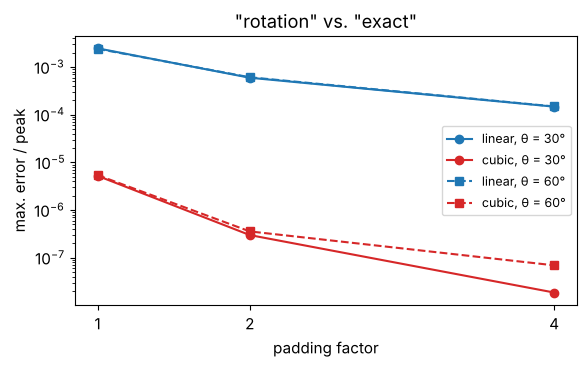

In [5]:
xo = grid1d(-90, 90, 256)
rows = []
for th in (30, 60):
    R = R_y(np.radians(th))
    t = time.perf_counter()
    exact = tilted_plane(u0, x, y, z0 + 20, WL, R=R, x_out=xo, method="exact")[0]
    t_exact = time.perf_counter() - t
    for kind in ("linear", "cubic"):
        for p in (1, 2, 4):
            t = time.perf_counter()
            rot = tilted_plane(u0, x, y, z0 + 20, WL, R=R, x_out=xo, method="rotation",
                               kind=kind, pad=p)[0]
            dt = time.perf_counter() - t
            rows.append((th, kind, p, np.abs(rot - exact).max()/np.abs(exact).max(), dt, t_exact))

print("theta  kind    pad   error     t_rotation  t_exact")
for r in rows:
    print("{:4d}°  {:6s} {:3d}   {:.1e}   {:6.3f} s   {:5.2f} s".format(*r))

fig, ax = plt.subplots(figsize=(6, 3.8))
for th, m in ((30, "o-"), (60, "s--")):
    for kind, col in (("linear", "C0"), ("cubic", "C3")):
        e = [r[3] for r in rows if r[0] == th and r[1] == kind]
        ax.semilogy((1, 2, 4), e, m, color=col, label="{}, θ = {}°".format(kind, th))
ax.set(xlabel="padding factor", ylabel="max. error / peak", xticks=(1, 2, 4),
       title='"rotation" vs. "exact"')
ax.legend(fontsize=9)
plt.tight_layout()

### Pitfall: the window

The `"rotation"` result is periodic in the output window (it is an inverse
FFT), the exact sum is not. If the beam does not fit into the window, it
wraps around. At $\theta = 75°$ the footprint is $1/\cos 75° \approx 3.9$ times wider; on
a window of $\pm 40\lambda$ the far, wider half of the beam is cut off and its tail
reappears on the other side (the exact sum simply shows the cut-out part). A
window that holds the footprint cures it; the remaining difference of
$7\cdot 10^{-3}$ is the weak tail at the far edge ($\hat x = -110\lambda$, $z = 226\lambda$, where the
beam is widest), which still wraps over to $\hat x = +110\lambda$. Also, the plane must not cross the source plane inside
the window (a `ValueError` says so).

window ±40 λ: max. difference 3.0e-01 of the peak


window ±110 λ: max. difference 7.2e-03 of the peak


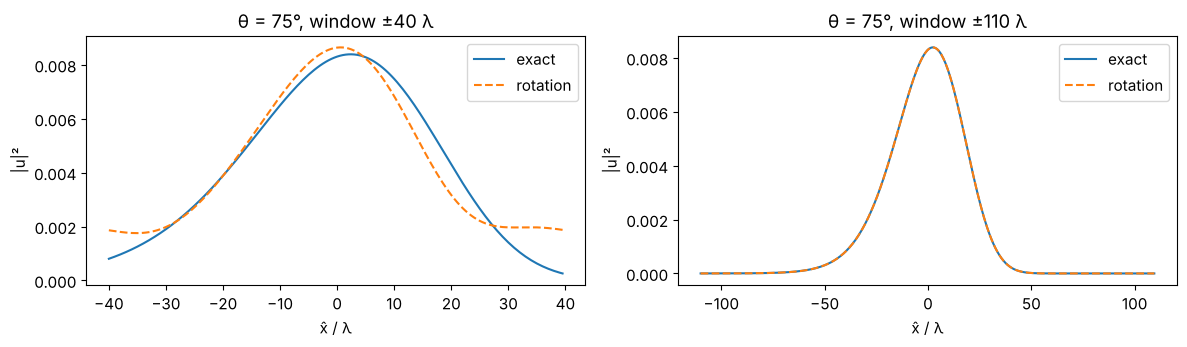

In [6]:
R = R_y(np.radians(75))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, xo, title in ((axs[0], grid1d(-40, 40, 160), "window ±40 λ"), (axs[1], grid1d(-110, 110, 440), "window ±110 λ")):
    ex = tilted_plane(u0, x, y, 120.0, WL, R=R, x_out=xo, y_out=np.array([0.0]), method="exact")[0][0]
    # "rotation" needs an equidistant 2D window; take its centre row:
    ro = tilted_plane(u0, x, y, 120.0, WL, R=R, x_out=xo, y_out=grid1d(-32, 32, 128),
                      method="rotation")[0][64]
    ax.plot(xo, np.abs(ex)**2, label="exact")
    ax.plot(xo, np.abs(ro)**2, "--", label="rotation")
    ax.set(xlabel="x̂ / λ", ylabel="|u|²", title="θ = 75°, " + title)
    ax.legend()
    print("{}: max. difference {:.1e} of the peak".format(title, np.abs(ro - ex).max()/np.abs(ex).max()))
plt.tight_layout()

## 4. Why the Jacobian is mandatory

The rotated spectrum is a density: $\hat A(\hat k_x, \hat k_y)\,d\hat k_x\,d\hat k_y =
A(k_x, k_y)\,dk_x\,dk_y$. The area elements differ by the Jacobian
$|\partial(k_x, k_y)/\partial(\hat k_x, \hat k_y)| = k_z/\hat k_z$, which for an on-axis beam is
$1/\cos\theta$. Leaving it out (`jacobian=False`, only for this demonstration) scales the
field by $\cos\theta$: the error is $1 - \cos\theta$, 50 % at 60°. Here the beam is rotated onto
planes through its waist, where the field at the origin must stay the same.

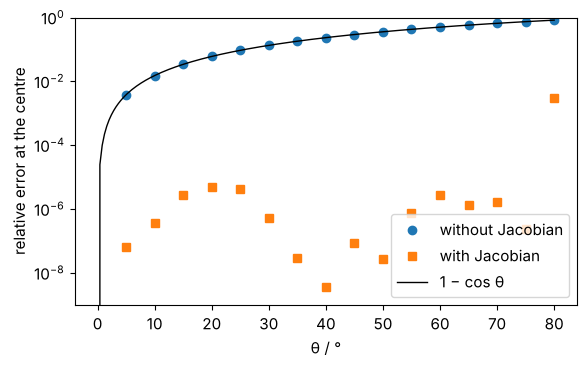

In [7]:
F0 = FT(u0)
kx, ky = frequencies(x), frequencies(y)
thetas = np.arange(0, 81, 5)
err_with, err_without = [], []
for th in thetas:
    R = R_y(np.radians(th))
    grid = dict(kx_out=kx - K*np.sin(np.radians(th)), ky_out=ky)
    a = inv_FT(rotate_angular_spectrum(F0, kx, ky, K, R, **grid))[N//2, N//2]
    b = inv_FT(rotate_angular_spectrum(F0, kx, ky, K, R, jacobian=False, **grid))[N//2, N//2]
    err_with.append(abs(a/u0[N//2, N//2] - 1))
    err_without.append(abs(b/u0[N//2, N//2] - 1))

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(thetas, err_without, "o", label="without Jacobian")
ax.plot(thetas, np.array(err_with) + 1E-16, "s", label="with Jacobian")
tt = np.linspace(0, 80, 200)
ax.plot(tt, 1 - np.cos(np.radians(tt)), "k-", lw=1, label="1 − cos θ")
ax.set(yscale="log", ylim=(1E-9, 1), xlabel="θ / °", ylabel="relative error at the centre")
ax.legend()
plt.tight_layout()

## 5. What is conserved: flux, not $\int |u|^2$

The integral of $|u_t|^2$ over a tilted plane grows as $1/\cos\theta$: the detector
catches the same beam on a larger area. The power *flux* through the plane,
$P = \sum |A|^2 \hat k_z/k$ (`power_flux()`), is the same for every plane the beam crosses.

flux deviation max: 1.1e-06


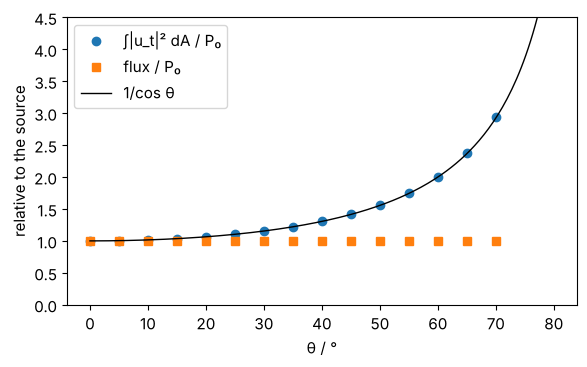

In [8]:
xo = grid1d(-180, 180, 512)
P0 = power_flux(ub, x, y, WL)
thetas = np.arange(0, 71, 5)
I_int, flux = [], []
for th in thetas:
    u_t, x_t, y_t, c = tilted_plane(ub, x, y, z0b, WL, R=R_y(np.radians(th)), x_out=xo,
                                    y_out=grid1d(-60, 60, 128), method="rotation")
    dA = (x_t[1] - x_t[0])*(y_t[1] - y_t[0])
    I_int.append(np.sum(np.abs(u_t)**2)*dA/P0)
    flux.append(power_flux(u_t, x_t, y_t, WL, k_carrier=c)/P0)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(thetas, I_int, "o", label="∫|u_t|² dA / P₀")
ax.plot(thetas, flux, "s", label="flux / P₀")
ax.plot(tt, 1/np.cos(np.radians(tt)), "k-", lw=1, label="1/cos θ")
ax.set(xlabel="θ / °", ylabel="relative to the source", ylim=(0, 4.5))
ax.legend()
plt.tight_layout()
print("flux deviation max: {:.1e}".format(np.max(np.abs(np.array(flux) - 1))))

## 6. The way back, and a tilted aperture

`reverse=True` makes the *source* the tilted plane: the field is given in the
coordinates of a plane rotated by $R$, and the target is the plane $z = z_0$ of the
unrotated frame. Internally this is the same propagation with $R^{-1} = R^T$.
Together with `k_carrier_in` (the carrier that was removed) it undoes a
forward step: forward onto a plane tilted about $x$ and $y$, back to $z = 0$.

round trip error: 4.8e-13 of the peak


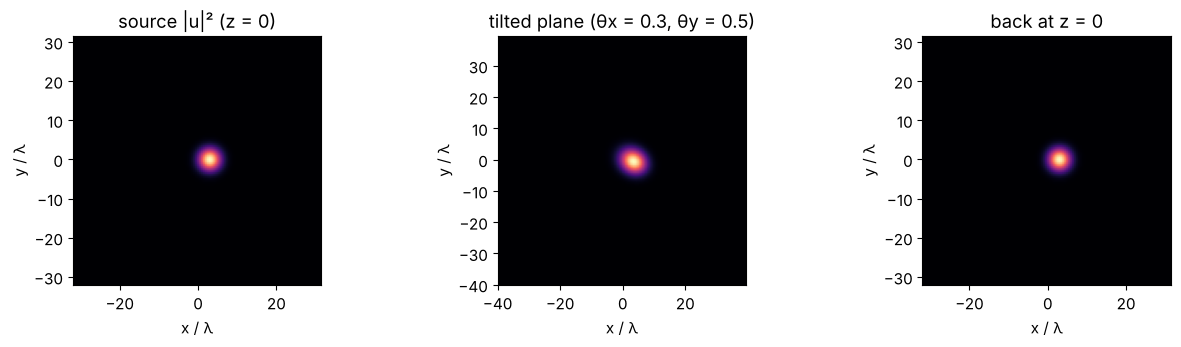

In [9]:
xs = grid1d(-32, 32, 128)
us = gaussian(xs, xs, 4.0, x0=3.0)
R = rotation_from_angles(0.3, 0.5)
xt = grid1d(-40, 40, 160)
u_t, x_t, y_t, c = tilted_plane(us, xs, xs, 40.0, WL, R=R, x_out=xt, y_out=xt)
back, *_ = tilted_plane(u_t, x_t, y_t, -40.0, WL, R=R, reverse=True, k_carrier_in=c,
                        x_out=xs, y_out=xs, remove_carrier=False)
print("round trip error: {:.1e} of the peak".format(np.abs(back - us).max()/np.abs(us).max()))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, f, xx, yy, title in ((axs[0], us, xs, xs, "source |u|² (z = 0)"),
                             (axs[1], u_t, x_t, y_t, "tilted plane (θx = 0.3, θy = 0.5)"),
                             (axs[2], back, xs, xs, "back at z = 0")):
    ax.imshow(np.abs(f)**2, extent=[xx[0], xx[-1], yy[0], yy[-1]], cmap="magma")
    ax.set(title=title, xlabel="x / λ", ylabel="y / λ")
plt.tight_layout()

A square aperture ($24\lambda \times 24\lambda$) in a plane tilted by 50° about $y$, lit by a
plane wave travelling along $z$. In the aperture's coordinates the incident
wave carries the carrier $\hat k_x = -k\sin\theta$, which `k_carrier_in` passes on. The
screens are parallel to $z = 0$. Seen from the beam, the aperture is
foreshortened by $\cos 50° = 0.64$ in $x$, and its left and right edges lie at
different distances: the near field is asymmetric and the far field
(here at $z = 400\lambda$) approaches that of a $15.4\lambda \times 24\lambda$ rectangle. The screens
must lie entirely in front of the (extended) aperture plane, here from
$z = 60\lambda$ on.

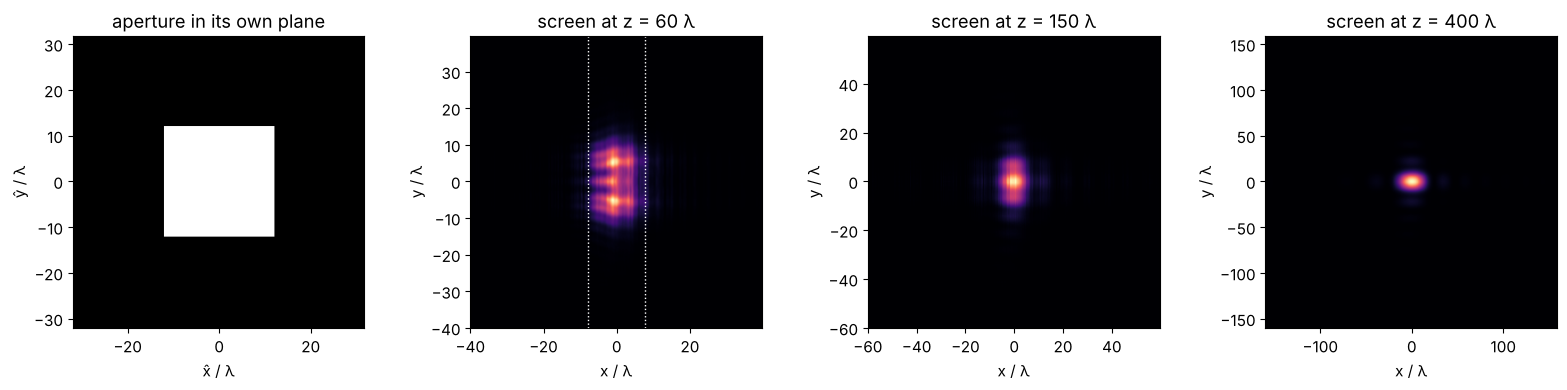

In [10]:
theta = np.radians(50)
R = R_y(theta)
xa = grid1d(-32, 32, 256)
Xa, Ya = np.meshgrid(xa, xa)
aperture = ((np.abs(Xa) <= 12) & (np.abs(Ya) <= 12)).astype(complex)
c_in = (-K*np.sin(theta), 0.0)

fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
axs[0].imshow(np.abs(aperture), extent=[xa[0], xa[-1], xa[0], xa[-1]], cmap="gray")
axs[0].set(title="aperture in its own plane", xlabel="x̂ / λ", ylabel="ŷ / λ")
for ax, d, half in ((axs[1], 60.0, 40), (axs[2], 150.0, 60), (axs[3], 400.0, 160)):
    xs_ = grid1d(-half, half, 256)
    u_s = tilted_plane(aperture, xa, xa, d, WL, R=R, reverse=True, k_carrier_in=c_in,
                       x_out=xs_, y_out=xs_, method="rotation", pad=2)[0]
    ax.imshow(np.abs(u_s)**2, extent=[xs_[0], xs_[-1], xs_[0], xs_[-1]], cmap="magma")
    ax.set(title="screen at z = {:g} λ".format(d), xlabel="x / λ", ylabel="y / λ")
axs[1].axvline(-12*np.cos(theta), color="w", ls=":", lw=1); axs[1].axvline(12*np.cos(theta), color="w", ls=":", lw=1)
plt.tight_layout()

## 7. Vector fields

`vectorial_tilted_plane()` computes $E_z$ of the source from $\nabla\cdot\mathbf E = 0$,
propagates all three Cartesian components and returns them in the
plane's axes: $\hat E_{\hat x} = \mathbf E\cdot\hat{\mathbf x}$, $\hat E_{\hat y} = \mathbf E\cdot\hat{\mathbf y}$ and the normal
component $\hat E_n = \mathbf E\cdot\hat{\mathbf n}$. For an $x$ polarized beam on a plane tilted by
$\theta$ about $y$ the field is mostly $\hat E_{\hat x} = E_x\cos\theta$ and $\hat E_n = E_x \sin\theta$; a
$y$ polarized beam stays tangential. A tight waist ($w_0 = 1.5\lambda$) also shows the
small cross-polarized and longitudinal parts of the beam itself.

x polarized, centre: |E_n/E_x^| = 1.0000, tan(theta) = 1.0000


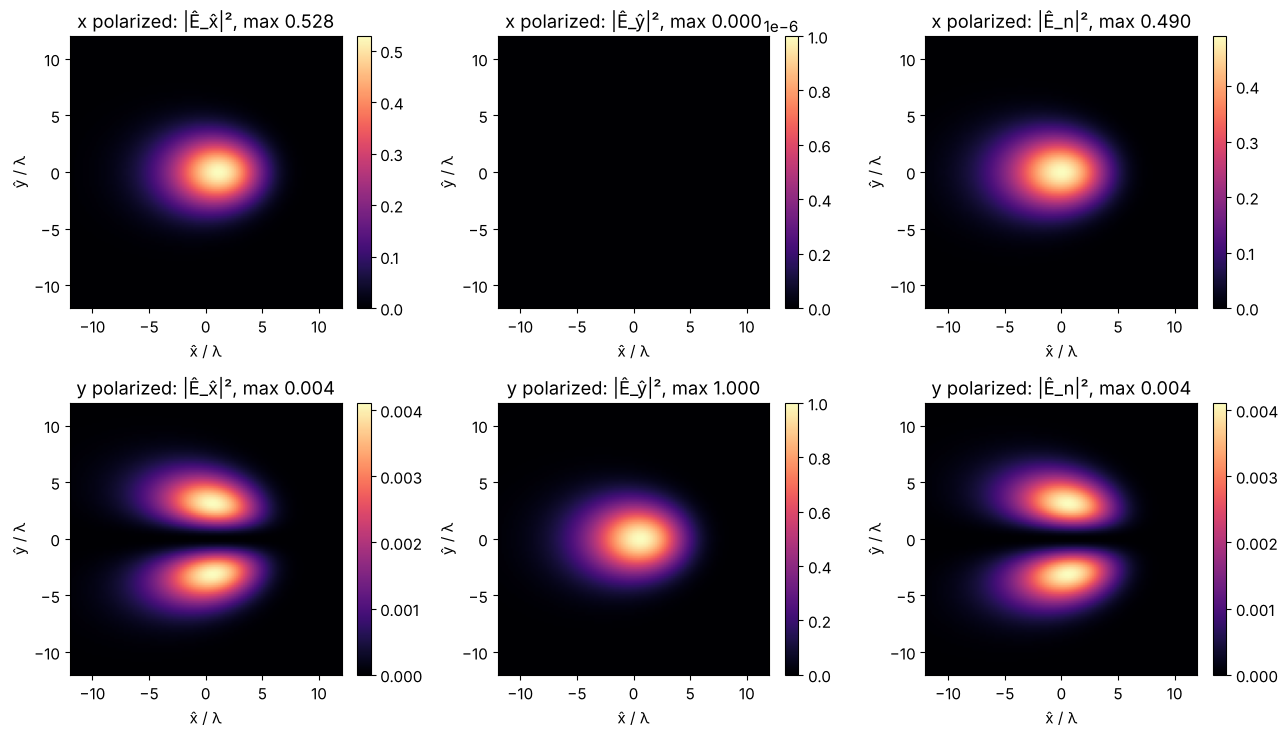

In [11]:
xv = grid1d(-24, 24, 192)
g = gaussian(xv, xv, 1.5)
theta = np.radians(45)
R = R_y(theta)
xo = grid1d(-16, 16, 160)
fig, axs = plt.subplots(2, 3, figsize=(13, 7.5))
for row, (pol, name) in enumerate(((np.array([1, 0]), "x"), (np.array([0, 1]), "y"))):
    field = np.stack([pol[0]*g, pol[1]*g], axis=-1)
    E_t, x_t, y_t, c = vectorial_tilted_plane(field, xv, xv, 20.0, WL, R=R, x_out=xo, y_out=xo)
    I_max = np.max(np.sum(np.abs(E_t)**2, axis=-1))
    for col, label in enumerate(("Ê_x̂", "Ê_ŷ", "Ê_n")):
        I = np.abs(E_t[..., col])**2/I_max
        im = axs[row, col].imshow(I, extent=[xo[0], xo[-1], xo[0], xo[-1]], cmap="magma",
                                  vmin=0, vmax=max(I.max(), 1E-6))
        axs[row, col].set(title="{} polarized: |{}|², max {:.3f}".format(name, label, I.max()),
                          xlabel="x̂ / λ", ylabel="ŷ / λ", xlim=(-12, 12), ylim=(-12, 12))
        plt.colorbar(im, ax=axs[row, col], fraction=0.046)
    if name == "x":
        centre = E_t[len(y_t)//2, len(x_t)//2]
        ratio = abs(centre[2]/centre[0])
plt.tight_layout()
print("x polarized, centre: |E_n/E_x^| = {:.4f}, tan(theta) = {:.4f}".format(ratio, np.tan(theta)))

## 8. Notes

- **Method choice.** By default `"exact"` is used for grids up to $N = 256$ when
  the rotation is about $x$ or $y$ (or finufft is installed, or $N \le 64$),
  and `"rotation"` (cubic interpolation, 2× padding) otherwise. Both agree to
  about $10^{-6}$ when the field fits into the window. Arbitrary, non-equidistant
  output points need `"exact"`.
- **Carrier.** `k_carrier` is the power weighted mean of $(\hat k_x, \hat k_y)$; the true field is
  $u_t\,e^{i(\hat k_{c,x}\hat x + \hat k_{c,y}\hat y)}$.
- **Forward waves only.** Plane waves that cross the target plane backwards
  ($\hat k_z \le 0$, only for spectra with angles beyond $90° - \theta$) and evanescent
  waves are dropped.
- **Windows and padding.** The footprint stretches by $1/\cos\theta$; choose `x_out`
  accordingly and pad the source when the beam spreads.

Tests: `test/test_tilted.py` checks $\theta = 0$ against `rayleigh_sommerfeld_I_TF()`,
plane waves and Gaussian beams against analytic fields at the plane's 3D
points, slice-by-slice propagation, the convergence of `"rotation"` to `"exact"`,
round trips, the way to parallel planes, flux conservation, the vectorial
components and the beam widths.